# Milestone 2: experiments after the first model

`milestone2_training.ipynb` is the first model (**v1**): fine-tuned MiniLM, test F1 0.906 vs. 0.863 for the pretrained model. This notebook records what we tried next, in order:

1. **Error analysis**: what v1 gets wrong on val, and how often Google's own cards are wrong.
2. **Data changes, one at a time** (each kept only if it improves val F1):
   - D. strip boilerplate such as "EN DIRECT" or "Live updates:" from headlines;
   - B. hard negatives: similar headlines from the same few days that are different stories;
   - A. extra positives mined across snapshots (same story, different angle);
   - C. translation: English pairs translated to French and the reverse.
3. **Cross-encoder**: a model that reads both headlines together, trained on the best data.
4. **Final test**: the model picked on val, scored once on the test set.

**Rule:** every decision is made on **val**. Augmented data is added to **train only**; val and test stay exactly as Google grouped them. Every experiment adds a row to `outputs/milestone2/experiments/log.csv`.

Set `SMOKE=1` in the environment to check the notebook end to end on small samples in a few minutes.

In [1]:
import itertools, json, os, random, re, sys, time
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sentence_transformers   # import before torch: the other order crashes on some Windows setups (DLL clash)
import torch
from sentence_transformers import SentenceTransformer, losses
from transformers import (AutoModelForSeq2SeqLM, AutoModelForSequenceClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup)
from sklearn.metrics import (accuracy_score, adjusted_rand_score, average_precision_score, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.cluster import AgglomerativeClustering

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'pairs').is_dir())
sys.path.insert(0, str(ROOT))
from src.embeddings import clean_headline

PAIRS, MODELS = ROOT / 'data' / 'pairs', ROOT / 'models'
OUT = ROOT / 'outputs' / 'milestone2' / 'experiments'
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
SEED = 6450
SMOKE = os.environ.get('SMOKE', '0') == '1'
LOG = OUT / ('log_smoke.csv' if SMOKE else 'log.csv')
if LOG.exists():
    LOG.unlink()               # each run of the notebook rebuilds the log from scratch

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

pairs = {s: pd.read_csv(PAIRS / f'{s}.csv', dtype={'timestamp': str}) for s in ['train', 'val', 'test']}

def best_threshold(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])

def evaluate(labels, scores, threshold):
    pred = (scores >= threshold).astype(int)
    return {'precision': precision_score(labels, pred, zero_division=0), 'recall': recall_score(labels, pred, zero_division=0),
            'f1': f1_score(labels, pred, zero_division=0), 'accuracy': accuracy_score(labels, pred),
            'roc_auc': roc_auc_score(labels, scores), 'pr_auc': average_precision_score(labels, scores)}

def pair_scores(model, df, prep=clean_headline, batch_size=64):
    """Cosine similarity per pair for a bi-encoder; every distinct headline is embedded once."""
    a, b = [prep(h) for h in df.headline_a], [prep(h) for h in df.headline_b]
    unique = list(dict.fromkeys(a + b))
    index = {h: i for i, h in enumerate(unique)}
    E = model.encode(unique, batch_size=batch_size, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
    return (E[[index[h] for h in a]] * E[[index[h] for h in b]]).sum(axis=1)

print('device:', DEVICE, '| SMOKE' if SMOKE else '| full run', '|', {s: len(d) for s, d in pairs.items()})

W1025 18:46:07.463000 20420 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


device: cuda | full run | {'train': 21907, 'val': 2850, 'test': 2457}


C:\Users\David\AppData\Local\Temp\ipykernel_20420\4227051718.py:10: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, losses


## 1. Error analysis on val

Score every val pair with v1, use v1's val threshold, and list the mistakes:
- **false positive:** v1 says "same story", but Google put the headlines in different cards;
- **false negative:** v1 says "different story", but Google put them in the same card.

A random sample of 30 of each is saved to `val_errors_sample.csv` and read by hand. The column `google_wrong` says whose mistake it is: `yes` = Google's grouping is wrong (the model is right), `unclear` = same broad topic but different events, `no` = the model is wrong.

In [2]:
v1 = SentenceTransformer(str(MODELS / 'minilm_finetuned'), device=DEVICE)
val = pairs['val'].copy()
val['score'] = pair_scores(v1, val)
t_v1 = best_threshold(val.label.values, val.score.values)
val['pred'] = (val.score >= t_v1).astype(int)
m = evaluate(val.label.values, val.score.values, t_v1)
print(f"v1 on val: threshold {t_v1:.3f}, F1 {m['f1']:.3f}, precision {m['precision']:.3f}, recall {m['recall']:.3f}")

val['error'] = np.select([(val.pred == 1) & (val.label == 0), (val.pred == 0) & (val.label == 1)],
                         ['false positive', 'false negative'], 'correct')
print(val.groupby(['error', 'edition']).size().unstack(fill_value=0))

sample = (val[val.error != 'correct'].groupby('error', group_keys=False)
             .apply(lambda d: d.sample(min(30, len(d)), random_state=SEED)))
cols = ['error', 'edition', 'score', 'headline_a', 'outlet_a', 'headline_b', 'outlet_b', 'timestamp']
sample = sample[cols].assign(score=lambda d: d.score.round(3), google_wrong='', note='')
path = OUT / 'val_errors_sample.csv'
if path.exists():              # never overwrite the hand-checked file
    print('kept existing', path.relative_to(ROOT))
else:
    sample.to_csv(path, index=False)
    print('saved', path.relative_to(ROOT))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

v1 on val: threshold 0.724, F1 0.882, precision 0.884, recall 0.881
edition         en-CA  fr-CA
error                       
correct          1351   1196
false negative     57     97
false positive     76     73
kept existing outputs\milestone2\experiments\val_errors_sample.csv


C:\Users\David\AppData\Local\Temp\ipykernel_20420\1474799571.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(min(30, len(d)), random_state=SEED)))


In [3]:
judged = pd.read_csv(OUT / 'val_errors_sample.csv').fillna('')
if (judged.google_wrong != '').any():
    display(pd.crosstab(judged.error, judged.google_wrong, margins=True))

google_wrong,no,unclear,yes,All
error,,,,
false negative,17,8,5,30
false positive,19,6,5,30
All,36,14,10,60


**What the hand check found** (60 mistakes): in about 17% Google's grouping is wrong (for example, "Iran closes Strait of Hormuz again" in two different cards on the same page), in about 23% the headlines share a broad topic but describe different events, and about 60% are real model mistakes. The real mistakes follow two patterns:

1. **Same topic, different event called "same story"**: Trump, Iran and Quebec politics headlines score high together even when they describe different events.
2. **Same story, different angle called "different"**: opinion columns, explainers and local angles (e.g. Winnipeggers in Puerto Vallarta vs. the El Mencho violence).

Hard negatives (B) target pattern 1; mined positives (A) target pattern 2; translation (C) targets the weaker French results; the cross-encoder targets both.

## 2. Experiment set-up

Same training recipe as v1 for every bi-encoder experiment (same seed, loss, learning rate, batch size, frozen vocabulary table, early stopping on val PR-AUC), so the only thing that changes is the data. Each result is logged with its val F1 overall and per language. Two reference rows come first: the pretrained model and v1.

In [4]:
CFG = dict(base_model='paraphrase-multilingual-MiniLM-L12-v2', epochs=3, batch_size=32, learning_rate=2e-5,
           weight_decay=0.01, warmup_ratio=0.1, max_grad_norm=1.0, max_seq_length=128, margin=0.5,
           freeze_word_embeddings=True, patience=1)
TRAIN, VAL = pairs['train'], pairs['val']
if SMOKE:
    CFG.update(epochs=1)
    TRAIN = TRAIN.sample(600, random_state=SEED).reset_index(drop=True)
    VAL = VAL.sample(500, random_state=SEED).reset_index(drop=True)

def log_result(step, name, description, scores, n_train, **extra):
    y = VAL.label.values
    t = best_threshold(y, scores)
    row = {'step': step, 'name': name, 'description': description, 'train_pairs': n_train, 'threshold': round(t, 4),
           **{f'val_{k}': round(v, 4) for k, v in evaluate(y, scores, t).items()}}
    for ed in ['en-CA', 'fr-CA']:
        mask = (VAL.edition == ed).values
        row[f'val_f1_{ed[:2]}'] = round(f1_score(y[mask], (scores[mask] >= t).astype(int)), 4)
    row.update(extra)
    log = pd.read_csv(LOG) if LOG.exists() else pd.DataFrame()
    if len(log):
        log = log[log.name != name]
    pd.concat([log, pd.DataFrame([row])]).sort_values('step').to_csv(LOG, index=False)
    print(f"[{step}] {name}: val F1 {row['val_f1']:.4f} (EN {row['val_f1_en']:.4f}, FR {row['val_f1_fr']:.4f}), PR-AUC {row['val_pr_auc']:.4f}")
    return row

def to_device(features):
    return {k: v.to(DEVICE) if torch.is_tensor(v) else v for k, v in features.items()}

def train_biencoder(train_df, tag, prep=clean_headline, cfg=CFG):
    """Fine-tune MiniLM with the v1 recipe; keep the epoch with the best val PR-AUC."""
    set_seed()
    model = SentenceTransformer(cfg['base_model'], cache_folder=str(MODELS), device=DEVICE)
    model.max_seq_length = cfg['max_seq_length']
    if cfg['freeze_word_embeddings']:
        next(m for n, m in model.named_modules() if n.endswith('word_embeddings')).requires_grad_(False)
    loss_fn = losses.OnlineContrastiveLoss(model, margin=cfg['margin'])
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=cfg['learning_rate'], weight_decay=cfg['weight_decay'])
    bs = cfg['batch_size']
    steps = int(np.ceil(len(train_df) / bs))
    sched = get_linear_schedule_with_warmup(opt, int(cfg['warmup_ratio'] * steps * cfg['epochs']), steps * cfg['epochs'])
    A, B = [prep(h) for h in train_df.headline_a], [prep(h) for h in train_df.headline_b]
    y = train_df.label.values.astype(np.float32)
    rng, best, bad, t0, history = np.random.default_rng(SEED), -1.0, 0, time.perf_counter(), []
    path = MODELS / 'exp' / tag
    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        order = rng.permutation(len(train_df))
        for s in range(steps):
            idx = order[s * bs:(s + 1) * bs]
            loss = loss_fn([to_device(model.tokenize([A[i] for i in idx])), to_device(model.tokenize([B[i] for i in idx]))],
                           torch.tensor(y[idx], device=DEVICE))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(params, cfg['max_grad_norm']); opt.step(); sched.step()
        model.eval()
        scores = pair_scores(model, VAL, prep)
        m = evaluate(VAL.label.values, scores, best_threshold(VAL.label.values, scores))
        history.append({'epoch': epoch, **m})
        print(f"  {tag} epoch {epoch}: val F1 {m['f1']:.4f}, PR-AUC {m['pr_auc']:.4f}")
        if m['pr_auc'] > best:
            best, bad, best_epoch, best_scores = m['pr_auc'], 0, epoch, scores
            model.save(str(path))
        else:
            bad += 1
            if bad >= cfg['patience']:
                break
    del model; torch.cuda.empty_cache()
    return {'path': path, 'prep': prep, 'scores': best_scores, 'best_epoch': best_epoch,
            'minutes': round((time.perf_counter() - t0) / 60, 2), 'history': pd.DataFrame(history)}

pretrained = SentenceTransformer(CFG['base_model'], cache_folder=str(MODELS), device=DEVICE)
CANDIDATES = {}   # name -> how to score it again in the final section
log_result(0, 'pretrained', 'pretrained MiniLM, no training', pair_scores(pretrained, VAL), 0)
v1_row = log_result(1, 'v1', 'fine-tuned MiniLM from milestone2_training.ipynb', pair_scores(v1, VAL), len(pairs['train']))
CANDIDATES['v1'] = {'kind': 'bi', 'path': MODELS / 'minilm_finetuned', 'prep': clean_headline}

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[0] pretrained: val F1 0.8327 (EN 0.8850, FR 0.7822), PR-AUC 0.9112
[1] v1: val F1 0.8823 (EN 0.9007, FR 0.8625), PR-AUC 0.9443


## 3. Building the extra training data (train only)

- **D. Boilerplate**: live-coverage and section labels at the start of a headline ("EN DIRECT |", "[Couverture en direct]", "Live updates:", "Dossier |", "Opinion:", "CP NewsAlert:") and counters like "(2 articles)" are removed before the headline reaches the model. They make unrelated live-coverage headlines look alike.
- **A. Mined positives**: if headline X shares a card with A on one page and with C on another page within 24 hours (same edition), then A and C are about the same story even though they never appeared together. Pairs that Google ever showed in *different* cards are skipped, at most 5 new pairs per X, at most 10,000 in total.
- **B. Hard negatives**: for each headline, the most similar headline (pretrained MiniLM) from the same edition, seen within 3 days, that it never shared a card with, directly or through another headline. (Same-day pairs are already in train, since the sample has one page per edition every 2 days.) Pairs scoring 0.75 or more are skipped: by hand, many of those are the same story covered on another day. At most 10,000.
- **C. Translation**: every train pair is translated into the other language (English↔French) with the Helsinki-NLP Marian models, keeping its label. The translations are made once by `src/translate_headlines.py` and kept in `data/augment/translations_train.csv`.

In [5]:
BOILERPLATE = [re.compile(p, re.I) for p in [
    r'^\s*\[\s*(couverture en direct|en direct|live|direct)\s*\]\s*',
    r'^\s*(en direct|live updates?|live|direct)\s*[:|,\-–]\s*',
    r'^\s*(dossier|opinion|analyse|analysis|chronique|éditorial|editorial|cp newsalert|breaking)\s*[:|]\s*']]
TRAILING = re.compile(r'\s*\(\d+ articles?\)\s*$', re.I)

def strip_boilerplate(text):
    t = clean_headline(text)
    changed = True
    while changed:
        changed = False
        for p in BOILERPLATE:
            new = p.sub('', t, count=1)
            if new != t:
                t, changed = new, True
    return TRAILING.sub('', t).strip() or clean_headline(text)

examples = ['EN DIRECT | 39e jour de la guerre au Moyen-Orient', '[Couverture en direct] La guerre en Iran est « pratiquement terminée »',
            'Dossier | Navires coincés dans le détroit d’Ormuz (2 articles)', 'Live updates: US Gulf allies fend off attacks',
            'Opinion: After shackling Canada to Trump’s war', 'Trump Live Updates: Minneapolis Crackdown']
for e in examples:
    print(f'{e!r:75} -> {strip_boilerplate(e)!r}')
heads = pd.unique(pd.concat([TRAIN.headline_a, TRAIN.headline_b]))
print(f"\nTrain headlines changed by D: {sum(strip_boilerplate(h) != clean_headline(h) for h in heads):,} of {len(heads):,}")

'EN DIRECT | 39e jour de la guerre au Moyen-Orient'                         -> '39e jour de la guerre au Moyen-Orient'
'[Couverture en direct] La guerre en Iran est « pratiquement terminée »'    -> 'La guerre en Iran est « pratiquement terminée »'
'Dossier | Navires coincés dans le détroit d’Ormuz (2 articles)'            -> 'Navires coincés dans le détroit d’Ormuz'
'Live updates: US Gulf allies fend off attacks'                             -> 'US Gulf allies fend off attacks'
'Opinion: After shackling Canada to Trump’s war'                            -> 'After shackling Canada to Trump’s war'
'Trump Live Updates: Minneapolis Crackdown'                                 -> 'Trump Live Updates: Minneapolis Crackdown'

Train headlines changed by D: 177 of 6,966


In [6]:
key = lambda a, b: (a, b) if a < b else (b, a)
pos, neg = TRAIN[TRAIN.label == 1], TRAIN[TRAIN.label == 0]
known_pos = {key(a, b) for a, b in zip(pos.headline_a, pos.headline_b)}
known_neg = {key(a, b) for a, b in zip(neg.headline_a, neg.headline_b)}
when = lambda ts: pd.Timestamp(ts[:8] + 'T' + ts[8:14]).value // 10**9   # seconds

# A. mined positives: two headlines that each shared a card with the same headline X within 24 h
neighbours = defaultdict(list)
for r in pos.itertuples():
    neighbours[r.headline_a].append((r.headline_b, when(r.timestamp), r.edition))
    neighbours[r.headline_b].append((r.headline_a, when(r.timestamp), r.edition))
rng = np.random.default_rng(SEED)
two_hop, mined = set(), []
for x, nb in neighbours.items():
    found = []
    for (h1, t1, e1), (h2, t2, e2) in itertools.combinations(nb, 2):
        k = key(h1, h2)
        if h1 == h2 or e1 != e2 or abs(t1 - t2) > 24 * 3600:
            continue
        two_hop.add(k)
        if k not in known_pos and k not in known_neg:
            found.append((h1, h2, e1, max(t1, t2)))
    for i in rng.permutation(len(found))[:5]:
        mined.append(found[i])
mined = list({key(a, b): (a, b, e, t) for a, b, e, t in mined}.values())
rng.shuffle(mined)
AUG = {'mined_positives': pd.DataFrame([{'timestamp': pd.Timestamp(t, unit='s').strftime('%Y%m%d%H%M%S'), 'edition': e, 'headline_a': a, 'headline_b': b,
                                         'label': 1, 'augmentation': 'mined_positive'} for a, b, e, t in mined[:10_000]])}
print(f"A. mined positives: {len(mined):,} found, {len(AUG['mined_positives']):,} kept")

# B. hard negatives: most similar headline from the same edition within 3 days that never shared a card with it
# (directly or via 2 hops). Same-day pairs are already in train: the sample has one page per edition every 2 days.
occ = pd.concat([TRAIN[['timestamp', 'edition', 'headline_a']].rename(columns={'headline_a': 'headline'}),
                 TRAIN[['timestamp', 'edition', 'headline_b']].rename(columns={'headline_b': 'headline'})])
occ = occ.sort_values('timestamp').drop_duplicates(['edition', 'headline'])      # first time each headline was seen
occ['t'] = occ.timestamp.map(when)
blocked = known_pos | two_hop
hard = {}
for ed, g in occ.groupby('edition'):
    hs, t = g.headline.tolist(), g.t.values
    E = pretrained.encode([clean_headline(h) for h in hs], batch_size=128, normalize_embeddings=True,
                          convert_to_numpy=True, show_progress_bar=False)
    S = E @ E.T
    S[np.abs(t[:, None] - t[None, :]) > 3 * 24 * 3600] = -1       # only headlines seen within 3 days
    np.fill_diagonal(S, -1)
    S[S >= 0.75] = -1                                             # above 0.75 it is often the same story on another day: skip
    for i, h in enumerate(hs):
        for j in np.argsort(-S[i])[:50]:
            k = key(h, hs[j])
            if S[i, j] <= -1 or k in blocked or k in known_neg:
                continue
            hard[k] = {'timestamp': g.timestamp.iloc[i], 'edition': ed, 'headline_a': k[0], 'headline_b': k[1],
                       'label': 0, 'augmentation': 'hard_negative', 'similarity': round(float(S[i, j]), 3)}
            break
hard = pd.DataFrame(list(hard.values()))
AUG['hard_negatives'] = hard.sample(min(10_000, len(hard)), random_state=SEED).reset_index(drop=True)
assert (AUG['hard_negatives'].headline_a != AUG['hard_negatives'].headline_b).all(), 'self-pair in hard negatives'
print(f"B. hard negatives: {len(hard):,} found, {len(AUG['hard_negatives']):,} kept, "
      f"median similarity {AUG['hard_negatives'].similarity.median():.2f} (random different-card pairs: "
      f"{np.median(pair_scores(pretrained, neg.sample(min(2000, len(neg)), random_state=SEED))):.2f})")
display(AUG['hard_negatives'].nlargest(5, 'similarity')[['edition', 'similarity', 'headline_a', 'headline_b']])
display(AUG['mined_positives'].head(5)[['edition', 'headline_a', 'headline_b']])

A. mined positives: 136 found, 136 kept


B. hard negatives: 5,892 found, 5,892 kept, median similarity 0.32 (random different-card pairs: 0.11)


,edition,similarity,headline_a,headline_b
153,fr-CA,0.750,Brusque escalade entre Israël et le Liban,"Liban: 31 morts, dont 3 enfants, dans la frapp..."
1914,en-CA,0.750,Cluster bombs: Unease grows over US sending cl...,"U.S. to send cluster munitions to Ukraine, but..."
2929,fr-CA,0.750,"Guerre en Ukraine, jour 789 | L'Ukraine et les...","Guerre en Ukraine, jour 792 | L'aide américain..."
3799,fr-CA,0.750,Escalade du conflit entre Israël et le Hezbollah,"Israël et le Hamas en guerre, jour 351 | Israë..."
650,en-CA,0.749,'Is this elbows down?': Manitoba premier quest...,When could prices start dropping as Canada axe...


,edition,headline_a,headline_b
0,fr-CA,Feux de forêt : encore des pannes...,Québec demande l'aide de l'armée pour combattr...
1,fr-CA,La prise de photo désormais obligatoire à la f...,Revue de presse | Les gens qui traversent la f...
2,fr-CA,« La loi sur la laïcité n’est pas respectée à ...,École Bedford | Consensus chez les caquistes p...
3,fr-CA,« La loi sur la laïcité n’est pas respectée à ...,Le drame de l’école Bedford: la faute des anti...
4,fr-CA,Sommet de la Francophonie : première rencontre...,Québec-France | Un « plan » pour doubler les é...


In [7]:
# C. translation: done once by src/translate_headlines.py (GPU, a few minutes) and cached in data/augment/
CACHE = ROOT / 'data' / 'augment' / 'translations_train.csv'
needed = set(zip(TRAIN.edition, TRAIN.headline_a)) | set(zip(TRAIN.edition, TRAIN.headline_b))
cache = pd.read_csv(CACHE) if CACHE.exists() else None
if cache is None or not needed <= set(zip(cache.edition, cache.headline)):
    import subprocess
    subprocess.run([sys.executable, str(ROOT / 'src' / 'translate_headlines.py')], check=True)
    cache = pd.read_csv(CACHE)
print(f'{len(cache):,} cached translations')

tr = {(e, h): t for e, h, t in cache[['edition', 'headline', 'translation']].itertuples(index=False)}
other = {'en-CA': 'fr-CA', 'fr-CA': 'en-CA'}
AUG['translation'] = pd.DataFrame({'timestamp': TRAIN.timestamp, 'edition': TRAIN.edition.map(other),
                                   'headline_a': [tr[(e, h)] for e, h in zip(TRAIN.edition, TRAIN.headline_a)],
                                   'headline_b': [tr[(e, h)] for e, h in zip(TRAIN.edition, TRAIN.headline_b)],
                                   'label': TRAIN.label, 'augmentation': 'translation'})
display(pd.DataFrame({'original': TRAIN.headline_a.head(4).values, 'translation': AUG['translation'].headline_a.head(4).values}))

6,966 cached translations


,original,translation
0,La Finlande annonce sa candidature «historique...,"Finland announces ""historical"" NATO application"
1,La Finlande confirme qu'elle demandera d'adhér...,Finland confirms that it will apply for NATO m...
2,La Finlande confirme qu'elle demandera d'adhér...,Finland confirms that it will apply for NATO m...
3,Guerre en Ukraine | La Finlande et la Suède bi...,War in Ukraine: Finland and Sweden soon to be ...


## 4. Bi-encoder experiments, one change at a time

Each step adds one change to the best setup so far and keeps it only if val F1 goes up. The starting point is v1.

In [8]:
best = {'f1': v1_row['val_f1'], 'prep': clean_headline, 'aug': [], 'name': 'v1'}
STEPS = [(2, 'D_boilerplate', 'strip boilerplate from headlines', {'prep': strip_boilerplate}),
         (3, 'B_hard_negatives', '+ hard negatives (similar headline within 3 days, different story)', {'aug': ['hard_negatives']}),
         (4, 'A_mined_positives', '+ positives mined across snapshots', {'aug': ['mined_positives']}),
         (5, 'C_translation', '+ every train pair translated EN<->FR', {'aug': ['translation']})]
RUNS = {}
for step, name, description, change in STEPS:
    prep = change.get('prep', best['prep'])
    aug = best['aug'] + change.get('aug', [])
    train_df = pd.concat([TRAIN] + [AUG[a] for a in aug], ignore_index=True)
    print(f"\n[{step}] {name}: {len(train_df):,} train pairs ({train_df.label.mean():.0%} same story), "
          f"boilerplate {'stripped' if prep is strip_boilerplate else 'kept'}, augmentation {aug or 'none'}")
    r = train_biencoder(train_df, name, prep)
    RUNS[name] = r
    row = log_result(step, name, description, r['scores'], len(train_df), best_epoch=r['best_epoch'], train_minutes=r['minutes'])
    kept = row['val_f1'] > best['f1']
    if kept:
        best = {'f1': row['val_f1'], 'prep': prep, 'aug': aug, 'name': name}
    CANDIDATES[name] = {'kind': 'bi', 'path': r['path'], 'prep': prep}
    log = pd.read_csv(LOG); log.loc[log.name == name, 'kept'] = kept; log.to_csv(LOG, index=False)
    print(f"  -> {'KEPT' if kept else 'dropped'}; best so far: {best['name']} (val F1 {best['f1']:.4f})")


[2] D_boilerplate: 21,907 train pairs (48% same story), boilerplate stripped, augmentation none


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

The `tokenize` method is deprecated, please use `preprocess` instead.


  D_boilerplate epoch 1: val F1 0.8807, PR-AUC 0.9444


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

  A_mined_positives epoch 3: val F1 0.8801, PR-AUC 0.9435
[4] A_mined_positives: val F1 0.8781 (EN 0.8938, FR 0.8606), PR-AUC 0.9458
  -> dropped; best so far: v1 (val F1 0.8823)

[5] C_translation: 43,814 train pairs (48% same story), boilerplate kept, augmentation ['translation']


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  C_translation epoch 1: val F1 0.8793, PR-AUC 0.9394


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  C_translation epoch 2: val F1 0.8785, PR-AUC 0.9391
[5] C_translation: val F1 0.8793 (EN 0.8938, FR 0.8632), PR-AUC 0.9394
  -> dropped; best so far: v1 (val F1 0.8823)


## 5. Cross-encoder

A bi-encoder turns each headline into a vector on its own and compares the vectors. A **cross-encoder** reads both headlines together, so it can weigh which words actually match (the event, the place, the person) rather than the general topic. It starts from `cross-encoder/mmarco-mMiniLMv2-L12-H384-v1` (multilingual MiniLM already trained to judge whether two texts match), is fine-tuned on the best data from section 4 with a binary loss, and scores each pair in both orders and averages them.

In [9]:
CE_NAME = 'cross-encoder/mmarco-mMiniLMv2-L12-H384-v1'

def ce_scores(model, tok, a, b, batch_size=128):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(a), batch_size):
            s = 0
            for x, y in [(a[i:i + batch_size], b[i:i + batch_size]), (b[i:i + batch_size], a[i:i + batch_size])]:
                f = tok(x, y, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)
                s = s + torch.sigmoid(model(**f).logits[:, 0].float())
            out.append((s / 2).cpu().numpy())
    return np.concatenate(out) if out else np.array([])

def train_crossencoder(train_df, tag, prep, cfg=CFG):
    set_seed()
    tok = AutoTokenizer.from_pretrained(CE_NAME, cache_dir=str(MODELS))
    model = AutoModelForSequenceClassification.from_pretrained(CE_NAME, cache_dir=str(MODELS), num_labels=1).to(DEVICE)
    bs = cfg['batch_size']
    steps = int(np.ceil(len(train_df) / bs))
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['learning_rate'], weight_decay=cfg['weight_decay'])
    sched = get_linear_schedule_with_warmup(opt, int(cfg['warmup_ratio'] * steps * cfg['epochs']), steps * cfg['epochs'])
    loss_fn = torch.nn.BCEWithLogitsLoss()
    A, B = [prep(h) for h in train_df.headline_a], [prep(h) for h in train_df.headline_b]
    va, vb = [prep(h) for h in VAL.headline_a], [prep(h) for h in VAL.headline_b]
    y = train_df.label.values.astype(np.float32)
    rng, best_auc, bad, t0, history = np.random.default_rng(SEED), -1.0, 0, time.perf_counter(), []
    path = MODELS / 'exp' / tag
    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        order = rng.permutation(len(train_df))
        for s in range(steps):
            idx = order[s * bs:(s + 1) * bs]
            swap = rng.random(len(idx)) < 0.5            # random order, so the model learns a symmetric score
            x = [B[i] if w else A[i] for i, w in zip(idx, swap)]
            z = [A[i] if w else B[i] for i, w in zip(idx, swap)]
            f = tok(x, z, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)
            loss = loss_fn(model(**f).logits[:, 0], torch.tensor(y[idx], device=DEVICE))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['max_grad_norm']); opt.step(); sched.step()
        scores = ce_scores(model, tok, va, vb)
        m = evaluate(VAL.label.values, scores, best_threshold(VAL.label.values, scores))
        history.append({'epoch': epoch, **m})
        print(f"  {tag} epoch {epoch}: val F1 {m['f1']:.4f}, PR-AUC {m['pr_auc']:.4f}")
        if m['pr_auc'] > best_auc:
            best_auc, bad, best_epoch, best_scores = m['pr_auc'], 0, epoch, scores
            model.save_pretrained(path); tok.save_pretrained(path)
        else:
            bad += 1
            if bad >= cfg['patience']:
                break
    del model; torch.cuda.empty_cache()
    return {'path': path, 'prep': prep, 'scores': best_scores, 'best_epoch': best_epoch,
            'minutes': round((time.perf_counter() - t0) / 60, 2), 'history': pd.DataFrame(history)}

train_df = pd.concat([TRAIN] + [AUG[a] for a in best['aug']], ignore_index=True)
print(f"cross-encoder data: {len(train_df):,} pairs (best bi-encoder setup: {best['name']})")
r = train_crossencoder(train_df, 'cross_encoder', best['prep'])
RUNS['cross_encoder'] = r
row = log_result(6, 'cross_encoder', f"cross-encoder (mMiniLM) on the {best['name']} data", r['scores'], len(train_df),
                 best_epoch=r['best_epoch'], train_minutes=r['minutes'])
CANDIDATES['cross_encoder'] = {'kind': 'cross', 'path': r['path'], 'prep': best['prep']}

cross-encoder data: 21,907 pairs (best bi-encoder setup: v1)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  cross_encoder epoch 1: val F1 0.8861, PR-AUC 0.9488


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  cross_encoder epoch 2: val F1 0.8849, PR-AUC 0.9427
[6] cross_encoder: val F1 0.8861 (EN 0.9043, FR 0.8663), PR-AUC 0.9488


## 6. Per-language thresholds and the pick

French headlines score differently from English ones, so one threshold per language (each chosen on val) is checked for the two best models. Then the model with the best val F1 is **picked before looking at the test set**.

cross_encoder: one threshold val F1 0.8861 | per language 0.8906 (EN 0.316, FR 0.635)
D_boilerplate: one threshold val F1 0.8807 | per language 0.8854 (EN 0.751, FR 0.761)

PICKED: cross_encoder (val F1 0.8906, per-language thresholds); best bi-encoder: D_boilerplate


,step,name,description,train_pairs,threshold,val_precision,val_recall,val_f1,val_accuracy,val_roc_auc,val_pr_auc,val_f1_en,val_f1_fr,best_epoch,train_minutes,kept,val_f1_per_language_threshold
0,0,pretrained,"pretrained MiniLM, no training",0,0.2936,0.8101,0.8566,0.8327,0.8442,0.9229,0.9112,0.8850,0.7822,NaN,NaN,NaN,NaN
1,1,v1,fine-tuned MiniLM from milestone2_training.ipynb,21907,0.7244,0.8840,0.8806,0.8823,0.8937,0.9501,0.9443,0.9007,0.8625,NaN,NaN,NaN,NaN
2,2,D_boilerplate,strip boilerplate from headlines,21907,0.7549,0.8862,0.8752,0.8807,0.8926,0.9491,0.9444,0.8998,0.8604,1.0,1.37,False,0.8854
3,3,B_hard_negatives,+ hard negatives (similar headline within 3 da...,27799,0.7504,0.9106,0.8372,0.8724,0.8891,0.9485,0.9453,0.8956,0.8470,1.0,1.71,False,NaN
4,4,A_mined_positives,+ positives mined across snapshots,22043,0.7325,0.8740,0.8822,0.8781,0.8891,0.9519,0.9458,0.8938,0.8606,2.0,2.04,False,NaN
5,5,C_translation,+ every train pair translated EN<->FR,43814,0.7753,0.8803,0.8783,0.8793,0.8909,0.9487,0.9394,0.8938,0.8632,1.0,2.74,False,NaN
6,6,cross_encoder,cross-encoder (mMiniLM) on the v1 data,21907,0.4117,0.8770,0.8953,0.8861,0.8958,0.9558,0.9488,0.9043,0.8663,1.0,1.34,NaN,0.8906


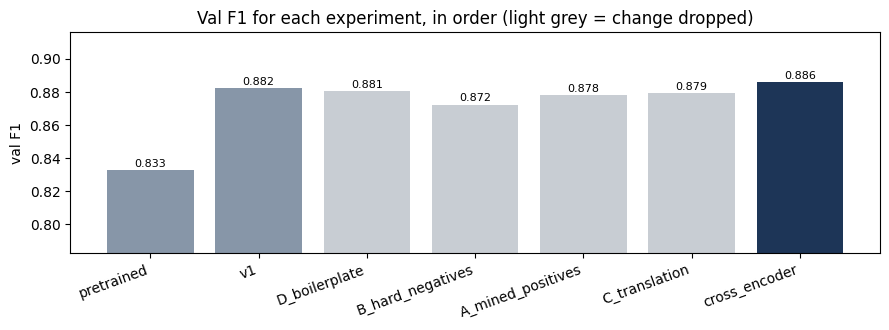

In [10]:
def per_language_f1(scores):
    y, pred = VAL.label.values, np.zeros(len(VAL), int)
    thresholds = {}
    for ed in ['en-CA', 'fr-CA']:
        mask = (VAL.edition == ed).values
        thresholds[ed] = best_threshold(y[mask], scores[mask])
        pred[mask] = (scores[mask] >= thresholds[ed]).astype(int)
    return f1_score(y, pred), thresholds

log = pd.read_csv(LOG)
top2 = log[log.name.isin(CANDIDATES) & (log.name != 'v1')].nlargest(2, 'val_f1').name.tolist()
for name in top2:
    f1, th = per_language_f1(RUNS[name]['scores'])
    CANDIDATES[name]['lang_thresholds'] = th
    print(f'{name}: one threshold val F1 {log.set_index("name").val_f1[name]:.4f} | per language {f1:.4f} '
          f'(EN {th["en-CA"]:.3f}, FR {th["fr-CA"]:.3f})')
    log.loc[log.name == name, 'val_f1_per_language_threshold'] = round(f1, 4)
log.to_csv(LOG, index=False)

log['best_val_f1'] = log[['val_f1', 'val_f1_per_language_threshold']].max(axis=1) if 'val_f1_per_language_threshold' in log else log.val_f1
pick = log[log.name.isin(CANDIDATES)].sort_values('best_val_f1', ascending=False).iloc[0]
PICK = pick['name']
USE_LANG = bool(pick.get('val_f1_per_language_threshold', np.nan) == pick.best_val_f1 and pick.best_val_f1 > pick.val_f1)
best_bi = log[log.name.isin([n for n, c in CANDIDATES.items() if c['kind'] == 'bi' and n != 'v1'])].nlargest(1, 'val_f1').name.iloc[0]
print(f'\nPICKED: {PICK} (val F1 {pick.best_val_f1:.4f}{", per-language thresholds" if USE_LANG else ""}); best bi-encoder: {best_bi}')
display(log.drop(columns=['best_val_f1']))

fig, ax = plt.subplots(figsize=(9, 3.4))
colors = ['#8796a8' if n in ('pretrained', 'v1') else '#1d3557' if (str(k) == 'True' or n == 'cross_encoder') else '#c8cdd3'
          for n, k in zip(log.name, log.get('kept', [None] * len(log)))]
ax.bar(range(len(log)), log.val_f1, color=colors)
for i, v in enumerate(log.val_f1):
    ax.text(i, v + 0.002, f'{v:.3f}', ha='center', fontsize=8)
ax.set_xticks(range(len(log)), log.name, rotation=20, ha='right')
ax.set_ylim(max(0, log.val_f1.min() - 0.05), min(1, log.val_f1.max() + 0.03))
ax.set(title='Val F1 for each experiment, in order (light grey = change dropped)', ylabel='val F1')
plt.tight_layout(); plt.savefig(OUT / 'experiments_history.png', dpi=160); plt.show()

## 7. Final test (run once)

The picked model is scored on the test set, next to the pretrained model and v1 for reference. The best bi-encoder and the cross-encoder are both shown, since they are two different architectures with different speed. Thresholds come from val. Scoring time on the test pairs is recorded as a rough speed comparison (Section 3 measures speed properly). Then every test page is grouped into cards and compared with Google's cards, as in the training notebook.

In [11]:
TEST = pairs['test'] if not SMOKE else pairs['test'].sample(500, random_state=SEED).reset_index(drop=True)

def load(name):
    c = CANDIDATES[name]
    if c['kind'] == 'bi':
        return c, SentenceTransformer(str(c['path']), device=DEVICE, cache_folder=str(MODELS)), None
    return c, AutoModelForSequenceClassification.from_pretrained(c['path']).to(DEVICE), AutoTokenizer.from_pretrained(c['path'])

def score(name, df):
    c, model, tok = load(name)
    t0 = time.perf_counter()
    if c['kind'] == 'bi':
        s = pair_scores(model, df, c['prep'])
    else:
        s = ce_scores(model, tok, [c['prep'](h) for h in df.headline_a], [c['prep'](h) for h in df.headline_b])
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    return s, time.perf_counter() - t0

CANDIDATES['pretrained'] = {'kind': 'bi', 'path': CFG['base_model'], 'prep': clean_headline}
FINAL = list(dict.fromkeys(['pretrained', 'v1', best_bi, 'cross_encoder', PICK]))
rows, THRESH = [], {}
for name in FINAL:
    val_s, _ = score(name, VAL)
    test_s, secs = score(name, TEST)
    lang = name == PICK and USE_LANG
    if lang:
        th = CANDIDATES[name]['lang_thresholds']
        pred = np.zeros(len(TEST), int)
        for ed, t in th.items():
            mask = (TEST.edition == ed).values
            pred[mask] = (test_s[mask] >= t).astype(int)
        t_all = None
    else:
        t_all = best_threshold(VAL.label.values, val_s)
        pred = (test_s >= t_all).astype(int)
    THRESH[name] = th if lang else t_all
    y = TEST.label.values
    for ed in ['all', 'en-CA', 'fr-CA']:
        mask = np.ones(len(TEST), bool) if ed == 'all' else (TEST.edition == ed).values
        rows.append({'model': name, 'picked': name == PICK, 'edition': ed,
                     'precision': precision_score(y[mask], pred[mask]), 'recall': recall_score(y[mask], pred[mask]),
                     'f1': f1_score(y[mask], pred[mask]), 'roc_auc': roc_auc_score(y[mask], test_s[mask]),
                     'pr_auc': average_precision_score(y[mask], test_s[mask]), 'n_pairs': int(mask.sum()),
                     'seconds_per_1000_pairs': round(secs / len(TEST) * 1000, 3)})
final = pd.DataFrame(rows)
final.to_csv(OUT / ('final_test_smoke.csv' if SMOKE else 'final_test.csv'), index=False)
display(final.pivot(index='model', columns='edition', values='f1').loc[FINAL].round(4))
final[final.edition == 'all'].round(4)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

edition,all,en-CA,fr-CA
model,,,
pretrained,0.8633,0.8622,0.8663
v1,0.9059,0.9167,0.8754
D_boilerplate,0.9060,0.9175,0.8739
cross_encoder,0.9056,0.9155,0.8754


,model,picked,edition,precision,recall,f1,roc_auc,pr_auc,n_pairs,seconds_per_1000_pairs
0,pretrained,False,all,0.8930,0.8355,0.8633,0.9472,0.9447,2457,0.075
3,v1,False,all,0.9156,0.8964,0.9059,0.9709,0.9658,2457,0.076
6,D_boilerplate,False,all,0.9186,0.8938,0.9060,0.9705,0.9657,2457,0.078
9,cross_encoder,True,all,0.9185,0.8930,0.9056,0.9702,0.9637,2457,0.742


In [12]:
FP = ROOT / 'data' / 'google_news_front_page'
snaps = pd.read_csv(FP / 'snapshots.csv', dtype={'timestamp': str})
keep = snaps[(snaps.purpose != 'repeat') & (snaps.exclude.astype(str).str.lower() != 'true')][['timestamp', 'edition']]
arts = pd.read_csv(FP / 'front_page_articles.csv', dtype={'timestamp': str}).merge(keep, on=['timestamp', 'edition'])
arts = arts[arts.section.isin(['Top stories', 'À la une']) & arts.headline.notna() & (arts.timestamp >= '20260501000000')]
pages = list(arts.groupby(['timestamp', 'edition']))
if SMOKE:
    pages = pages[:6]

def similarity_matrix(name, model, tok, headlines):
    c = CANDIDATES[name]
    h = [c['prep'](x) for x in headlines]
    if c['kind'] == 'bi':
        E = model.encode(h, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
        return E @ E.T
    i, j = np.triu_indices(len(h), 1)
    S = np.eye(len(h))
    S[i, j] = S[j, i] = ce_scores(model, tok, [h[k] for k in i], [h[k] for k in j])
    return S

rows = []
for name in FINAL:
    c, model, tok = load(name)
    for (ts, ed), page in pages:
        truth = page.card.values
        t = THRESH[name][ed] if isinstance(THRESH[name], dict) else THRESH[name]
        if len(page) < 2:
            pred = np.zeros(len(page), int)
        else:
            dist = np.clip(1 - similarity_matrix(name, model, tok, page.headline.tolist()), 0, None)
            pred = AgglomerativeClustering(n_clusters=None, metric='precomputed', linkage='average',
                                           distance_threshold=1 - t).fit_predict(dist)
        google = {frozenset(np.where(truth == k)[0]) for k in set(truth)}
        ours = {frozenset(np.where(pred == k)[0]) for k in set(pred)}
        rows.append({'model': name, 'edition': ed, 'ari': adjusted_rand_score(truth, pred),
                     'exact_cards': len(google & ours), 'google_cards': len(google)})
    del model; torch.cuda.empty_cache()
g = pd.DataFrame(rows)
grouping = (g.groupby('model').apply(lambda d: pd.Series({'ARI': d.ari.mean(), 'exact cards': d.exact_cards.sum() / d.google_cards.sum(),
                                                         'pages': len(d)})).loc[FINAL])
grouping.to_csv(OUT / ('final_grouping_smoke.csv' if SMOKE else 'final_grouping.csv'))
grouping.round(4)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

C:\Users\David\AppData\Local\Temp\ipykernel_20420\3947515731.py:39: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  grouping = (g.groupby('model').apply(lambda d: pd.Series({'ARI': d.ari.mean(), 'exact cards': d.exact_cards.sum() / d.google_cards.sum(),


,ARI,exact cards,pages
model,,,
pretrained,0.7015,0.6049,112.0
v1,0.7761,0.6719,112.0
D_boilerplate,0.7908,0.6875,112.0
cross_encoder,0.8138,0.7098,112.0
